# Simulación de trayectorias con activos reales

---
Nombre: **Alan Jesús Hernández Soto**  
Carrera: **Ingeniería Financiera**  
Materia: **Simulación de Procesos Financieros**  
Tipo de trabajo: **Clase**

---
Se analizan precios históricos de META y se generan trayectorias simuladas.

In [8]:
import pandas as pd
import yfinance as yf
import numpy as np

prices = yf.download('META', period='6mo')
prices

C:\Users\1\AppData\Local\Temp\ipykernel_21108\3627757764.py:5: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download('META', period='6mo')
[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,META,META,META,META,META
Date,,,,,
2026-03-24,591.903870,599.970040,589.987177,598.073271,10739700
2026-03-25,593.870483,602.635404,592.383047,597.713861,12585000
2026-03-26,546.601624,582.000875,542.418802,581.491740,35780100
2026-03-27,524.819031,542.668394,519.368427,539.174392,30133000
2026-03-30,535.460754,538.625305,527.634164,535.460754,22795200
...,...,...,...,...,...
2026-09-17,681.771973,682.661285,666.523996,681.901875,15928000
2026-09-18,665.225037,689.605821,660.278928,688.076998,27596400


## Resumen de los datos

Se revisan las medidas estadísticas principales de los precios descargados.

In [9]:
prices.describe()

Price,Close,High,Low,Open,Volume
Ticker,META,META,META,META,META
count,127.000000,127.000000,127.000000,127.000000,1.270000e+02
mean,609.659865,619.166459,600.588305,609.273109,1.835609e+07
std,43.845238,44.088573,42.570162,42.419798,8.283065e+06
min,524.819031,538.625305,519.368427,525.585226,8.660100e+06
25%,577.823975,591.259929,570.085918,579.588736,1.304695e+07
50%,602.644409,612.947766,595.637435,604.013304,1.628350e+07
75%,634.186249,645.193130,624.507155,640.260830,2.019690e+07
max,744.099976,763.900024,739.510010,747.599976,5.276500e+07


## Precio de cierre

Se grafica la evolución del precio de cierre de META durante los últimos seis meses.

Text(0, 0.5, 'Precio de Cierre (USD)')

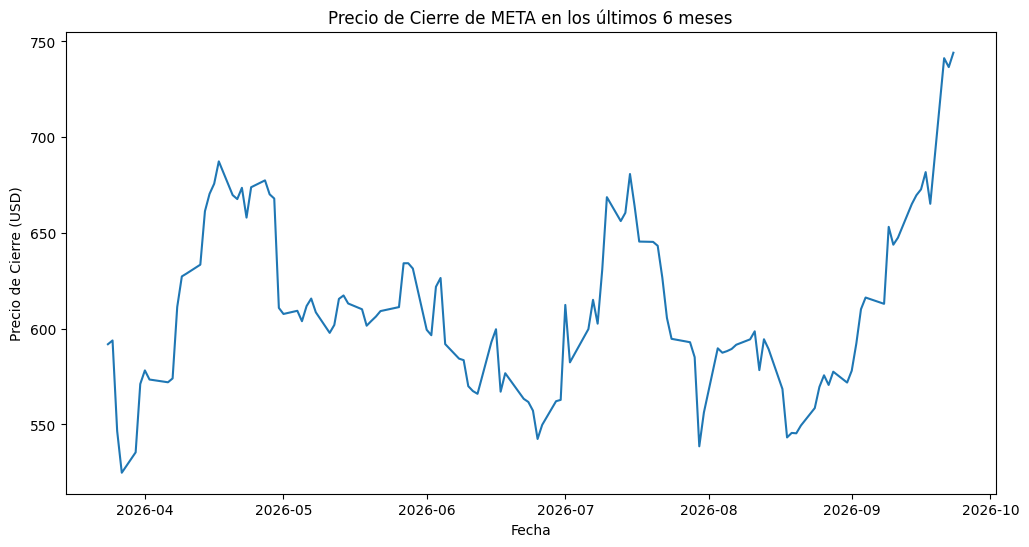

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.title('Precio de Cierre de META en los últimos 6 meses')
plt.plot(prices['Close'])
plt.xlabel('Fecha')
plt.ylabel('Precio de Cierre (USD)')

## Rendimientos diarios

Se calculan los rendimientos porcentuales diarios y se observa su distribución.

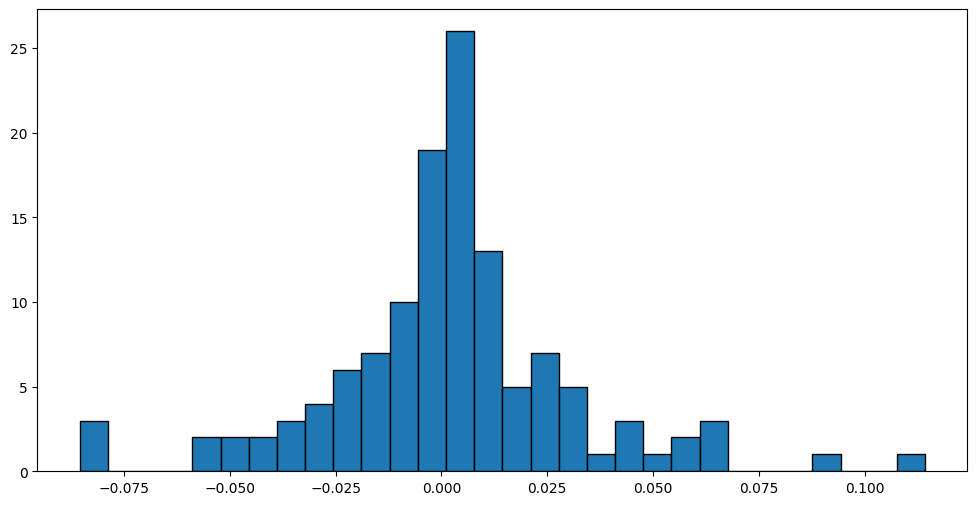

Ticker,META
count,126.000000
mean,0.002251
std,0.029616
min,-0.085500
25%,-0.009602
50%,0.002823
75%,0.013298
max,0.114285


In [11]:
rets = prices['Close'].pct_change().dropna()
plt.figure(figsize=(12, 6))
plt.hist(rets, bins=30, edgecolor='black')
plt.show()
rets.describe()

## Payoffs de opciones

Se calculan los payoffs de opciones put y call: europea, asiática y lookback.

In [12]:
closes = prices.loc[:, 'Close'].values
k = closes[0]
St = closes[-1]

#put
payoff_put_eu = np.maximum(k - St, 0)
payoff_put_asian = np.maximum(k - np.mean(closes), 0)
payoff_put_lookback = max(closes) - St

#call
payoff_call_eu = np.maximum(St - k, 0)
payoff_call_asian = np.maximum(np.mean(closes) - k, 0)
payoff_call_lookback = St - np.min(closes)

print(payoff_put_eu, payoff_put_asian, payoff_put_lookback)
print(payoff_call_eu, payoff_call_asian, payoff_call_lookback)

[0.] [0.] [0.]
[152.19610596] [17.7559949] [219.28094482]


## Datos para la simulación

Se usan precios anteriores para estimar la media y la volatilidad de los rendimientos.

In [13]:
close_prev = yf.download('META', start='2025-09-22', end='2026-03-25')['Close']
mean = close_prev.pct_change().dropna().mean()
std = close_prev.pct_change().dropna().std()
cp = close_prev.values.flatten()
cp[-1]

C:\Users\1\AppData\Local\Temp\ipykernel_21108\2344071479.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  close_prev = yf.download('META', start='2025-09-22', end='2026-03-25')['Close']
[*********************100%***********************]  1 of 1 completed


np.float64(591.9038696289062)

## Trayectorias simuladas

Se generan posibles precios futuros con Movimiento Browniano Geométrico.

In [14]:
def create_paths(S0, r, sigma, T, steps, n_paths):
    print(type(S0), type(r), type(sigma), type(T), type(steps), type(n_paths))
    dt = T / steps
    paths = np.zeros((steps + 1, n_paths))
    paths[0, :] = S0
    for t in range(steps):
        paths[t+1, :] = paths[t, :] * np.exp((r - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * np.random.normal(0, 1, n_paths))
    return paths

paths = create_paths(S0=cp[-1], r=mean.values[0], sigma=std.values[0], T=0.5, steps=126, n_paths=1000)
paths.shape

<class 'numpy.float64'> <class 'numpy.float64'> <class 'numpy.float64'> <class 'float'> <class 'int'> <class 'int'>


(127, 1000)

## Comparación gráfica

Se muestran los precios históricos junto con las trayectorias simuladas.

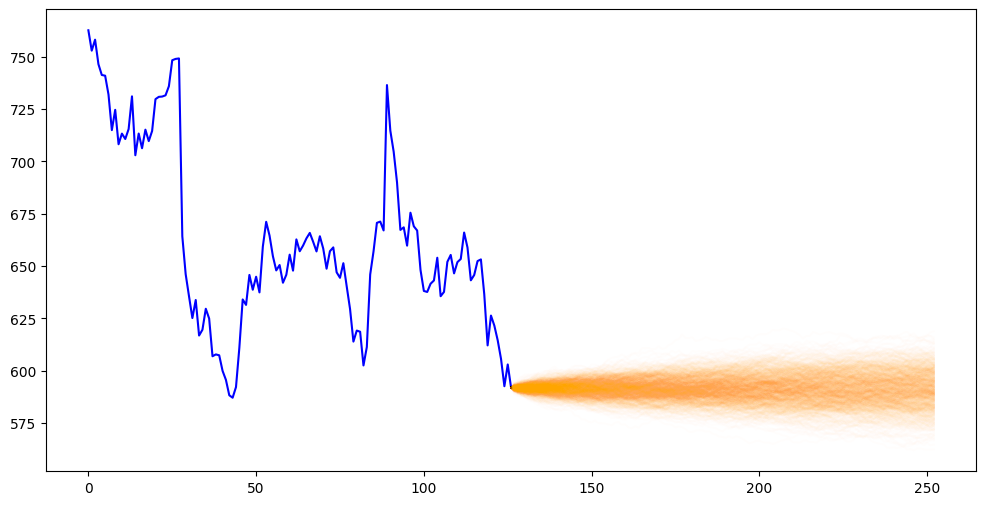

In [15]:
dias_cp = np.linspace(0, 126, 127)
dias_sim = np.arange(126, 253)

plt.figure(figsize=(12, 6))
plt.plot(dias_cp, cp, label='Precio Histórico', color='blue')
for i in range(paths.shape[1]):
    plt.plot(dias_sim, paths[:, i], color='orange', alpha=0.01)
plt.show()

## Conclusión

El análisis de los precios de META permitió observar su comportamiento reciente y la variación de sus rendimientos diarios. Con estos datos se calcularon distintos *payoffs* de opciones y se generaron trayectorias simuladas . La simulación ayuda a representar posibles escenarios futuros, aunque los resultados dependen de los datos históricos y no garantizan el comportamiento real del precio.